# Imports

In [1]:
import numpy as np
from qiskit_aer import AerSimulator
from matplotlib import pyplot as plt
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

# Constants

In [2]:
P_ARRAY = np.arange(0,0.11,0.02)
N_ARRAY = np.arange(2,15,2)
ITERS = 100
print(P_ARRAY)
print(N_ARRAY)

[0.   0.02 0.04 0.06 0.08 0.1 ]
[ 2  4  6  8 10 12 14]


# Functions

In [3]:
def getSimonsCircuit(n:int) -> QuantumCircuit:
    '''
    Get the circuit for the n-qubit Simon's algorithm with the 1s secret string.
    Args:
        n (int): The number of qubits in the input register.
    Returns:
        QuantumCircuit: The Simon's algorithm circuit.
    '''
    
    # Create the circuit for this run on Simon's algorithm.
    qreg = QuantumRegister(2*n)
    creg = ClassicalRegister(n)
    circuit = QuantumCircuit(qreg, creg)
    for m in range(n):
        circuit.h(m)
    for m in range(n):
        circuit.cx(m, n+m)
    for m in range(n):
        circuit.cx(0, n+m)
        # break   # Uncomment for "simple" oracle.
    for m in range(n):
        circuit.h(m)
    for i in range(n):
        circuit.measure(i, i)
    return circuit

In [4]:
def executeNoisyCircuit(n:int, shots:int, p1q:float, p2q:float) -> list:
    '''
    Execute a noisy version of the Simon's circuit with depolarizing noise.
    Args:
        n (int): The number of qubits.
        shots (int): The number of shots.
        p1q (float): The probability of depolarizing error for one-qubit gates.
        p2q (float): The probability of depolarizing error for two-qubit gates.
    Returns:
        list: A list of noisy samples.
    '''
    
    circ = getSimonsCircuit(n)
    noiseModel = NoiseModel()
    depolarizing1q = depolarizing_error(p1q, 1)
    depolarizing2q = depolarizing_error(p2q, 2)
    noiseModel.add_all_qubit_quantum_error(
        depolarizing1q,
        ['id', 'rz', 'sx', 'x']
    )
    noiseModel.add_all_qubit_quantum_error(
        depolarizing2q,
        ['cx']
    )
    noisySim = AerSimulator(noise_model=noiseModel)
    passManager = generate_preset_pass_manager(
        optimization_level=3, backend=noisySim
    )
    noisyCirc = passManager.run(circ)
    result = noisySim.run(noisyCirc, shots=shots).result()
    counts = result.get_counts()
    noisySamples = []
    for key, value in counts.items():
        for i in range(value):
            noisySamples.append(np.array(list(map(int, key))))
    return noisySamples

executeNoisyCircuit(2, 20, 0.1, 0.1)

[array([0, 1]),
 array([0, 1]),
 array([0, 1]),
 array([1, 0]),
 array([1, 0]),
 array([1, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([0, 0]),
 array([1, 1]),
 array([1, 1]),
 array([1, 1]),
 array([1, 1]),
 array([1, 1]),
 array([1, 1]),
 array([1, 1])]

In [5]:
def getAllBitstrings(n:int, includeZero:bool=True) -> list:
    '''
    Returns a list of all bitstrings of length n.
    Args:
        n (int): the length of the bitstrings.
        includeZero (bool): whether to include all-zeros string (default: True).
    Returns:
        A list of all bitstrings of length n.
    '''

    bitstrings = []
    start = 0 if includeZero else 1
    for x in range(start, 2**n):
        bitstrings.append(np.array(list(map(int, list(f'{x:0{n}b}')))))
    return bitstrings

getAllBitstrings(3)

[array([0, 0, 0]),
 array([0, 0, 1]),
 array([0, 1, 0]),
 array([0, 1, 1]),
 array([1, 0, 0]),
 array([1, 0, 1]),
 array([1, 1, 0]),
 array([1, 1, 1])]

In [6]:
def solveSubsystem(subsystem:np.array) -> np.array:
    '''
    Solves the given subsystem of equations.
    Args:
        subsystem (np.array): the subsystem of equations to solve.
    Returns:
        A bitstring that satisfies the subsystem of equations,
        or the all-zeros string if no such bitstring exists.
    '''

    n = len(subsystem[0])
    zeros = np.zeros(n-1, int)
    bitstrings = getAllBitstrings(n, False)
    for bits in bitstrings:
        if np.allclose((subsystem @ bits) % 2, zeros):
            return bits
    return np.zeros(n, int)

print(solveSubsystem(np.array([np.array([1, 0, 1]), np.array([1, 1, 0])])))
print(solveSubsystem(np.array([np.array([0, 1, 1]), np.array([0, 1, 0])])))

[1 1 1]
[1 0 0]


In [7]:
def validateSubsystem(subsystem:np.array, secretString:np.array) -> np.array:
    '''
    Validate that the provided secret string solves the given subsystem.
    Args:
        subsystem (np.array): the subsystem of equations to solve.
        secretString (np.array): the secret string.
    Returns:
        The secret string if it satisfies the subsystem of equations,
        or the all-zeros string if no such bitstring exists.
    '''

    n = len(subsystem[0])
    zeros = np.zeros(n-1, int)
    if np.allclose((subsystem @ secretString) % 2, zeros):
        return secretString
    return np.zeros(n, int)

print(solveSubsystem(np.array([np.array([1, 0, 1]), np.array([1, 1, 0])])))
print(solveSubsystem(np.array([np.array([0, 1, 1]), np.array([0, 1, 0])])))

[1 1 1]
[1 0 0]


In [8]:
def solveNoisySystem(
        noisySamples:np.array,
        secretString:np.array,
        trials:int=50,
        solveSystem:bool=True
    ) -> bool:
    '''
    Solves the given noisy system of equations.
    Args:
        noisySamples (np.array): the noisy samples of equations.
        secretString (np.array): the secret string.
        trials (int): the number of random subsystems to try (default: 50).
        solveSystem (bool): Whether to solve or validate the system.
            Validating uses knowledge of s for computational efficiency.
    Returns:
        True if the secret string can be recovered, False otherwise.
    '''

    n = len(secretString)
    for i in range(trials):
        indices = np.random.choice(len(noisySamples), n-1, replace=False)
        subsystem = np.array([noisySamples[i] for i in indices])
        if solveSystem:
            solution = solveSubsystem(subsystem)
        else:
            solution = validateSubsystem(subsystem, secretString)
        if np.allclose(solution, secretString):
            return True
    return False

solveNoisySystem(
    [
        np.array([0, 0, 1]),
        np.array([1, 0, 1]),
        np.array([1, 1, 0]),
        np.array([0, 0, 0]),
        np.array([1, 1, 0]),
        np.array([0, 0, 0]),
        np.array([0, 1, 1]),
        np.array([0, 1, 1]),
        np.array([0, 0, 0]),
        np.array([0, 0, 0]),
        np.array([1, 0, 0]),
        np.array([0, 0, 0]),
        np.array([0, 0, 1]),
        np.array([0, 1, 1]),
        np.array([0, 1, 1]),
        np.array([1, 1, 0]),
        np.array([1, 0, 1]),
        np.array([0, 1, 0]),
        np.array([0, 1, 0]),
        np.array([1, 1, 0]),
        np.array([1, 0, 0]),
        np.array([0, 1, 0]),
        np.array([1, 0, 1])
    ], [1, 1, 1]
)

True

# Experiment

In [9]:
try:
    successHeatmap = np.load('data/successHeatmap.npy')
    with open('data/iterations.txt', 'r') as file:
        start = int(file.read())
except:
    successHeatmap = np.zeros((len(N_ARRAY), len(P_ARRAY)))
    start = 1
for iter in range(start, ITERS + 1):
    print(f'Iteration {iter}')
    for i, n in enumerate(N_ARRAY):
        print(f'n = {n}:\t', end=' ')
        for j, p1q in enumerate(P_ARRAY):
            print(f'p = {np.round(p1q, 2)}', end=' ')
            shots = n + 20  # n + 20 chosen to make P(failure|p=0) < 1/1,000,000
            secretString = np.array([1] * n)
            noisySamples = executeNoisyCircuit(n, shots, p1q, 0)
            successHeatmap[i,j] += solveNoisySystem(
                np.array(noisySamples), secretString, solveSystem=False
            )
            print('\n', end='')
        np.save('data/successHeatmap.npy', successHeatmap)
        with open('data/iterations.txt', 'w+') as file:
            file.write(str(iter))

successHeatmap

Iteration 1
n = 2:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 4:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 6:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 8:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 10:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 12:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 14:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
Iteration 2
n = 2:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 4:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 6:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 8:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 10:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 12:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
n = 14:	 p = 0.0 
p = 0.02 
p = 0.04 
p = 0.06 
p = 0.08 
p = 0.1 
Iteration 3
n = 2:	 p = 0.0 
p = 0.02 
p = 0.0

array([[100., 100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100.,  98.],
       [100., 100.,  91.,  79.,  73.,  62.],
       [100.,  88.,  52.,  37.,  31.,  19.],
       [100.,  57.,  17.,   5.,   8.,  10.],
       [100.,  24.,   7.,   4.,   4.,   3.],
       [100.,   4.,   1.,   0.,   1.,   1.]])

In [10]:
x_ticks = np.arange(0,6)
y_ticks = np.arange(0,7)
P_ARRAY = np.arange(0,0.11,0.02)
N_ARRAY = np.arange(2,15,2)[::-1]

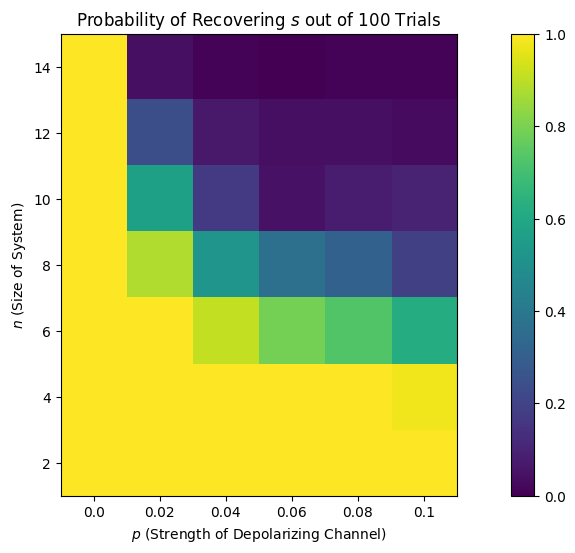

In [13]:
fig = plt.figure(figsize=(14,6))
with open('data/iterations.txt', 'r') as file:
    numTrials = int(file.read())
successHeatmap = np.load('data/successHeatmap.npy')
successHeatmap /= numTrials
plt.imshow(successHeatmap[::-1])
plt.xlabel(r'$p$ (Strength of Depolarizing Channel)')
plt.ylabel(r'$n$ (Size of System)')
plt.xticks(x_ticks, P_ARRAY)
plt.yticks(y_ticks, N_ARRAY)
plt.colorbar()
plt.title(fr'Probability of Recovering $s$ out of {int(numTrials)} Trials')
plt.show()